In [1]:
import importlib.util
import os
from math import pi
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeBrisbane

In [2]:
shots = 100
RUN_IONQ_CLOUD = False  # Requires qiskit-ionq and an IonQ API credential

In [3]:
if RUN_IONQ_CLOUD:
    if importlib.util.find_spec('qiskit_ionq') is None:
        raise RuntimeError('Install qiskit-ionq in the project environment to run the hosted IonQ demo')
    if not any(os.environ.get(key) for key in ('QISKIT_IONQ_API_TOKEN', 'IONQ_API_KEY', 'IONQ_API_TOKEN')):
        raise RuntimeError('Configure an IonQ API credential locally; do not put it in the notebook')
    from qiskit_ionq import IonQProvider
    backend = IonQProvider().get_backend('ionq_simulator')
    backend.set_options(noise_model='aria-1')
    backend_label = 'IonQ hosted aria-1 noise simulator'
else:
    backend = AerSimulator.from_backend(FakeBrisbane())
    backend_label = 'local Aer with IBM FakeBrisbane noise'
print('Backend:', backend_label, '| shots:', shots)

Backend: local Aer with IBM FakeBrisbane noise | shots: 100


The original example selects IonQ's hosted `aria-1` noise model. Set `RUN_IONQ_CLOUD = True` only after installing `qiskit-ionq` and configuring an IonQ API credential locally. This checked-in run uses the 100-shot local Aer fallback derived from the ZIP's `test_noisy_sim.py`; its IBM FakeBrisbane noise is **not** an IonQ model. The archive preserves the unmodified original notebook.

In [4]:
# The local Aer fallback is transpiled after binding the parameter.
# IonQ compiles the submitted QIS circuit through its provider.

In [5]:
# The provided demo originally used BackendSamplerV2; the backend run API
# works for both the IonQ noisy simulator and local Aer fallback.

In [6]:
theta_vec = ParameterVector(r"$\theta$", length=1)

ansatz = QuantumCircuit(3)
ansatz.h(0)
ansatz.cx(0, 1)
ansatz.rxx(theta_vec[0], 1, 2)
ansatz.measure_all()  # don't forget this line

In [7]:
# The circuit below measures all three qubits at the end.

In [8]:
qc = ansatz.assign_parameters({theta_vec[0]: 2*pi/5})

In [9]:
# The noisy simulator returns sampled integer counts; the ideal IonQ
# simulator instead returns probabilities, so keep this demo in noisy mode.

Backend: local Aer with IBM FakeBrisbane noise
Counts: {'001': 1, '100': 4, '110': 10, '010': 2, '000': 29, '101': 18, '111': 2, '011': 34}
Circuit-shots: 100; elapsed: 0.919 s; sample-to-ideal TVD: 0.1100
Cloud jobs: 0 ; local service charges: $0
Figure: /home/bobjoe/PycharmProjects/AEGQA/outputs/png/ionq_reference_demo_100shot.png


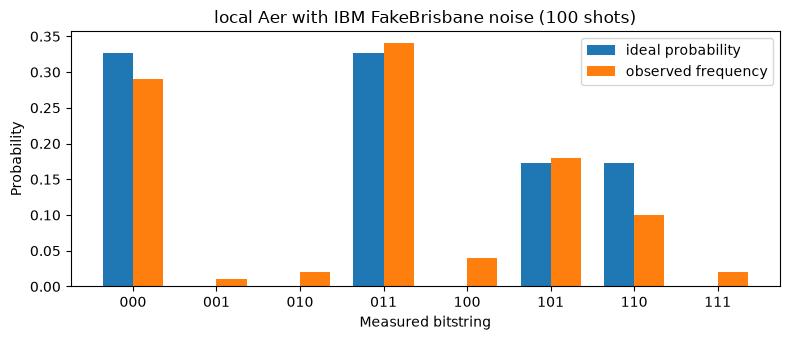

In [11]:
from pathlib import Path

qc_to_run = qc if RUN_IONQ_CLOUD else transpile(qc, backend, seed_transpiler=23)
run_kwargs = {'shots': shots}
if not RUN_IONQ_CLOUD:
    run_kwargs['seed_simulator'] = 23
started = perf_counter()
result = backend.run(qc_to_run, **run_kwargs).result()
elapsed = perf_counter() - started
counts = result.get_counts()
assert sum(counts.values()) == shots
ideal = Statevector.from_instruction(qc.remove_final_measurements(inplace=False)).probabilities()
measured = np.array([counts.get(format(i, '03b'), 0) / shots for i in range(8)])
tvd = float(np.abs(measured - ideal).sum() / 2)
print('Backend:', backend_label)
print('Counts:', counts)
print(f'Circuit-shots: {shots}; elapsed: {elapsed:.3f} s; sample-to-ideal TVD: {tvd:.4f}')
print('Cloud jobs:', int(RUN_IONQ_CLOUD), '; local service charges: $0' if not RUN_IONQ_CLOUD else '; see IonQ account billing')
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(8)
ax.bar(x - .18, ideal, .36, label='ideal probability')
ax.bar(x + .18, measured, .36, label='observed frequency')
ax.set_xticks(x, [format(i, '03b') for i in x])
ax.set(xlabel='Measured bitstring', ylabel='Probability', title=backend_label + ' (100 shots)')
ax.legend()
fig.tight_layout()
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
figure_path = root / 'outputs/png/ionq_reference_demo_100shot.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160)
print('Figure:', figure_path)
plt.show()

### Result and limits

This executed 100-shot run used **local Aer with IBM FakeBrisbane noise**. It yielded counts totaling 100 and sample-to-ideal TVD of 0.1100; this combines device-model effects and finite-shot variation, so it does not isolate either effect. Execution after compilation took 0.919 seconds on this machine. The run used one circuit, 100 circuit-shots, zero cloud jobs and $0 cloud service charges. Local CPU cost was not priced. The figure shows the ideal distribution against the sampled counts without hiding low-frequency outcomes.

The original IonQ `aria-1` notebook remains in `qml_demo_noisy_and_qpu.zip`. This extracted notebook has an optional hosted IonQ path (`RUN_IONQ_CLOUD = True`), which requires the `qiskit-ionq` package and an IonQ credential. Neither was available in this environment, so no IonQ device-model result is claimed. The `test_noisy_sim.py` example in the same archive was also run locally at 100 shots. The IBM hardware and IBM account-backed examples were not run.